In [17]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.model_selection import StratifiedKFold, cross_validate , train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET_COLUMN = "diabetes"

print("Libraries imported successfully.")

Libraries imported successfully.


1. load the dataset

In [18]:
df = pd.read_csv(r"C:\Users\User\PyCharmMiscProject\diabetes prediction model\csv file\diabetes_prediction_dataset.csv")

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


2. understanding the data and doing quality assessment

This checks:

- Data types
- Missing values
- Duplicate rows
- Target balance
- Unique categorical values

In [19]:
print("DATA TYPES")
display(df.dtypes.to_frame("Data Type"))

print("\nMISSING VALUES")
display(df.isna().sum().to_frame("Missing Values"))

print(f"\nDuplicate rows: {df.duplicated().sum():,}")

print("\nGENDER VALUES")
print(df["gender"].value_counts(dropna=False))

print("\nSMOKING HISTORY VALUES")
print(df["smoking_history"].value_counts(dropna=False))

print("\nTARGET DISTRIBUTION")
target_summary = pd.DataFrame({
    "Count": df[TARGET_COLUMN].value_counts().sort_index(),
    "Percentage": (
        df[TARGET_COLUMN].value_counts(normalize=True).sort_index() * 100
    ).round(2)
})
display(target_summary)

DATA TYPES


,Data Type
gender,str
age,float64
hypertension,int64
heart_disease,int64
smoking_history,str
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64



MISSING VALUES


,Missing Values
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0



Duplicate rows: 3,854

GENDER VALUES
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

SMOKING HISTORY VALUES
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

TARGET DISTRIBUTION


,Count,Percentage
diabetes,,
0,91500,91.5
1,8500,8.5


1. Data cleaning

Exact duplicates are removed to reduce repeated information and unnecessary computation.The target and binary medical-history variables are converted to numeric form. Invalid target values are excluded.


In [20]:
original_rows = len(df)

df = df.drop_duplicates().reset_index(drop=True)

removed_duplicates = original_rows - len(df)

binary_columns = ["hypertension", "heart_disease", TARGET_COLUMN]

for column in binary_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

numeric_columns = [
    "age",
    "hypertension",
    "heart_disease",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level",
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df = df[df[TARGET_COLUMN].isin([0, 1])].copy()
df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(int)

print(f"Removed duplicate rows: {removed_duplicates:,}")
print(f"Clean dataset shape: {df.shape}")

Removed duplicate rows: 3,854
Clean dataset shape: (96146, 9)


1. Exploratory Data Analysis

Exploratory analysis helps identify:

- Class imbalance
- Distribution patterns
- Potentially influential clinical variables
- Correlations between numerical features

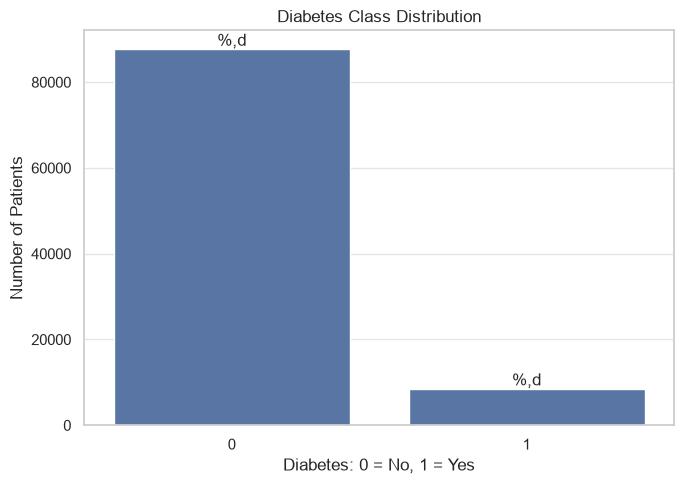

In [21]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x=TARGET_COLUMN)

for container in ax.containers:
    ax.bar_label(container, fmt="%,d")

plt.title("Diabetes Class Distribution")
plt.xlabel("Diabetes: 0 = No, 1 = Yes")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

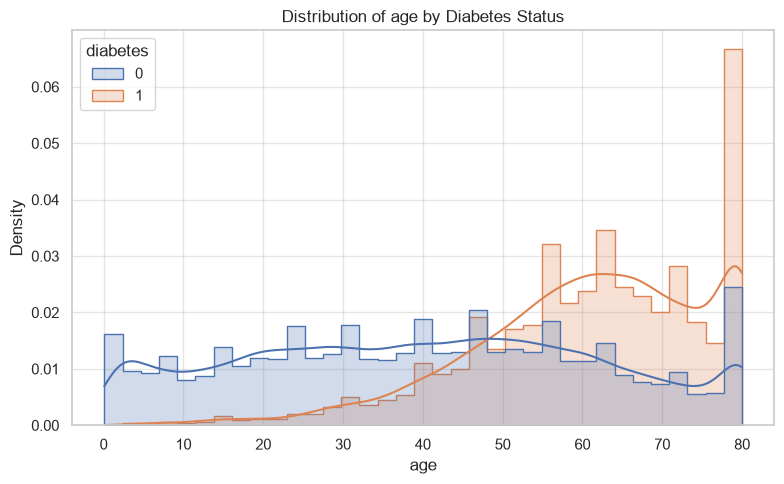

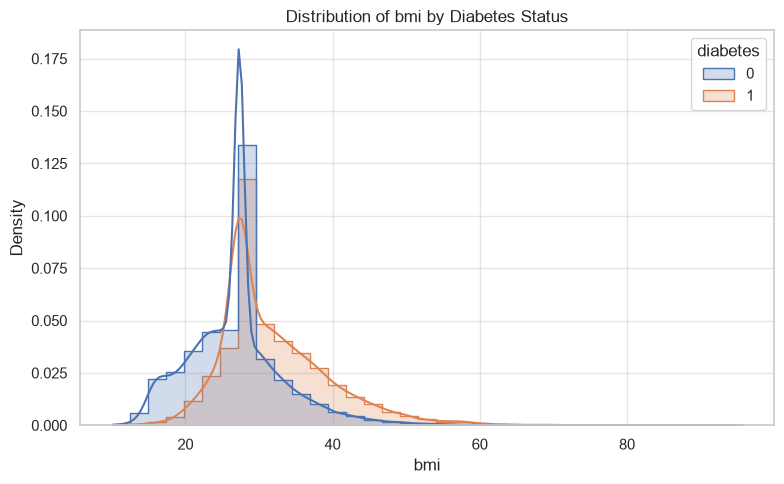

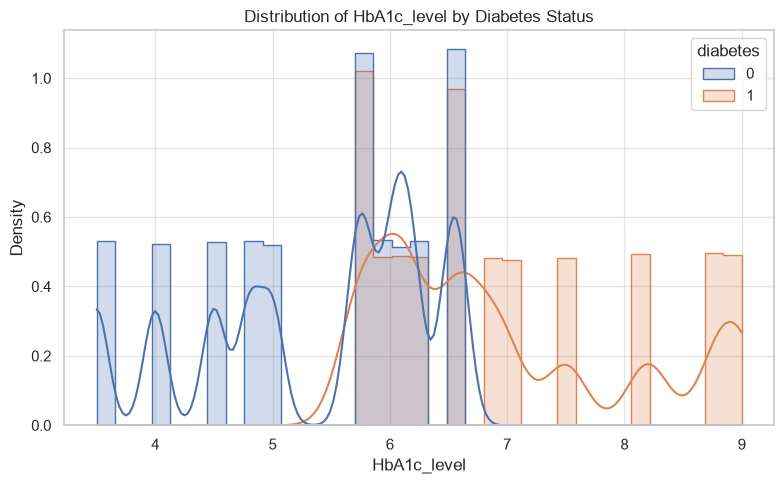

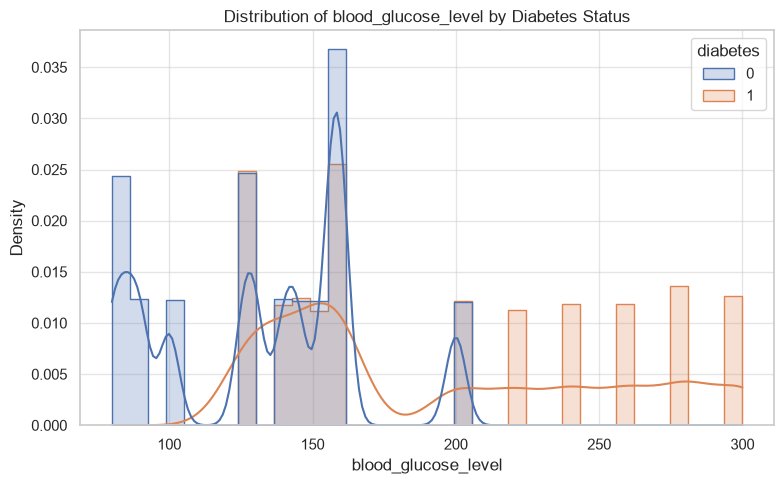

In [22]:
plot_features = [
    "age",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level",
]

for feature in plot_features:
    plt.figure(figsize=(8, 5))
    sns.histplot(
        data=df,
        x=feature,
        hue=TARGET_COLUMN,
        bins=35,
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
    )
    plt.title(f"Distribution of {feature} by Diabetes Status")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()

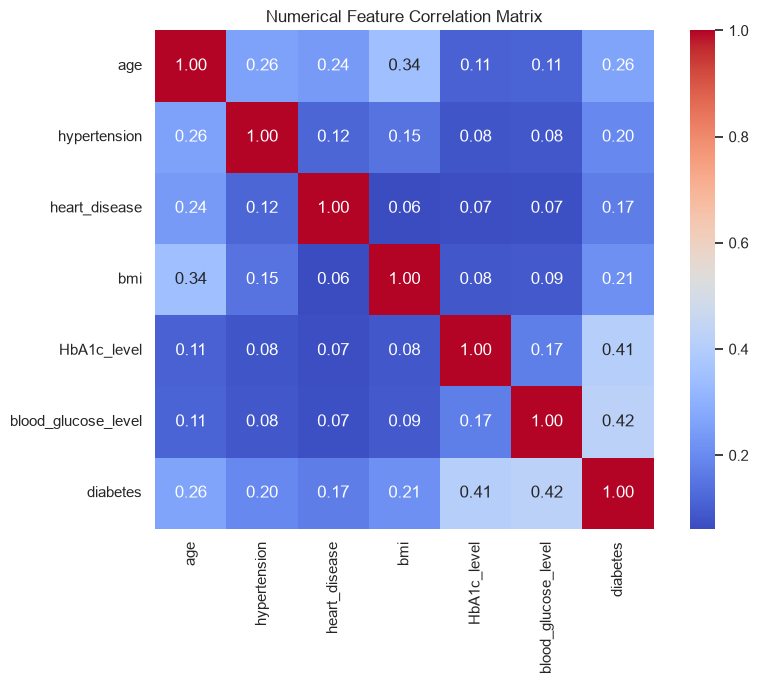

In [23]:
correlation_features = numeric_columns + [TARGET_COLUMN]

plt.figure(figsize=(9, 7))
sns.heatmap(
    df[correlation_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
)
plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()

1. Define features and target

The target variable is `diabetes`.The dataset contains both numerical and categorical predictors, so separate preprocessing pipelines are created for each data type.

In [24]:
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

categorical_features = [
    "gender",
    "smoking_history",
]

numeric_features = [
    "age",
    "hypertension",
    "heart_disease",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level",
]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows: {len(X_test):,}")
print(f"Training diabetes rate: {y_train.mean() * 100:.2f}%")
print(f"Testing diabetes rate: {y_test.mean() * 100:.2f}%")

Training rows: 76,916
Testing rows: 19,230
Training diabetes rate: 8.82%
Testing diabetes rate: 8.82%


1. Preprocessing pipeline

 Numerical features

- Missing values are imputed using the median
- Features are standardized using `StandardScaler`

Categorical features

- Missing values are imputed using the most frequent category
- Categories are transformed using one-hot encoding

Class imbalance

SMOTE creates synthetic minority-class examples. It is applied only inside the training pipeline to prevent data leakage.

In [25]:
numeric_transformer = ImbPipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = ImbPipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


1. Model selection

Four models are compared:

Logistic Regression
A strong interpretable baseline for binary classification.

Random Forest
Captures nonlinear relationships and interactions between features.

Support Vector Classifier
Effective for complex decision boundaries, although computationally expensive on large datasets.

XGBoost
A powerful gradient-boosting algorithm commonly used for structured tabular data.

In [26]:
RUN_SVC = True

# RBF SVC is expensive on large datasets. Train it on a stratified sample.
SVC_MAX_TRAINING_ROWS = 10_000

# Store estimators only. build_pipeline() will add preprocessing and SMOTE
# exactly once for every model.
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2_000,
        random_state=RANDOM_STATE,
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=350,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    "SVC": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=False,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),

    "XGBoost": XGBClassifier(
        n_estimators=350,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}


def build_pipeline(model):
    """Create one clean preprocessing -> SMOTE -> model pipeline."""
    return ImbPipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("smote", SMOTE(random_state=RANDOM_STATE)),
            ("model", model),
        ]
    )


pipelines = {
    model_name: build_pipeline(model)
    for model_name, model in models.items()
}

print("Model pipelines created successfully.")
for model_name, pipeline in pipelines.items():
    print(f"{model_name}: {list(pipeline.named_steps)}")


Model pipelines created successfully.
Logistic Regression: ['preprocessor', 'smote', 'model']
Random Forest: ['preprocessor', 'smote', 'model']
SVC: ['preprocessor', 'smote', 'model']
XGBoost: ['preprocessor', 'smote', 'model']


1. Five-fold Stratified Cross-Validation

Stratified cross-validation preserves the class distribution in every fold.

The following metrics are calculated:

- Accuracy
- Precision
- Recall
- F1 score
- ROC-AUC

For medical screening, recall is especially important because false negatives may leave high-risk patients undetected.

In [27]:
FAST_CV_MODE = True

cv = StratifiedKFold(
    n_splits=3 if FAST_CV_MODE else 5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv_results_rows = []

# SVC is deliberately excluded from fast cross-validation.
# It can still be trained and evaluated once on the test set.
fast_cv_models = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost",
]

for model_name, pipeline in pipelines.items():

    if FAST_CV_MODE and model_name not in fast_cv_models:
        print(f"Skipping {model_name} during fast cross-validation.")
        continue

    print(f"Cross-validating {model_name}...")

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,

        # Use available processor cores.
        # Use n_jobs=2 or n_jobs=4 if -1 causes your computer to freeze.
        n_jobs=-1,

        return_train_score=False,

        # Continue running even if one fold fails.
        error_score="raise",
    )

    cv_results_rows.append({
        "Model": model_name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "F1 Mean": scores["test_f1"].mean(),
        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "ROC-AUC SD": scores["test_roc_auc"].std(),
        "Fit Time Mean": scores["fit_time"].mean(),
    })

cv_results = (
    pd.DataFrame(cv_results_rows)
    .sort_values("ROC-AUC Mean", ascending=False)
    .reset_index(drop=True)
)

display(
    cv_results.style.format({
        "Accuracy Mean": "{:.4f}",
        "Precision Mean": "{:.4f}",
        "Recall Mean": "{:.4f}",
        "F1 Mean": "{:.4f}",
        "ROC-AUC Mean": "{:.4f}",
        "ROC-AUC SD": "{:.4f}",
        "Fit Time Mean": "{:.2f} seconds",
    })
)

Cross-validating Logistic Regression...
Cross-validating Random Forest...
Skipping SVC during fast cross-validation.
Cross-validating XGBoost...


,Model,Accuracy Mean,Precision Mean,Recall Mean,F1 Mean,ROC-AUC Mean,ROC-AUC SD,Fit Time Mean
0,XGBoost,0.9689,0.9181,0.7106,0.8010,0.9782,0.0006,8.18 seconds
1,Random Forest,0.9537,0.7230,0.7707,0.7460,0.9709,0.0005,41.97 seconds
2,Logistic Regression,0.8876,0.4327,0.8811,0.5804,0.9621,0.0008,1.32 seconds


1. Final training and test-set evaluation

Each model is trained on the training set and evaluated on the untouched test set.

The test set provides a more realistic estimate of how the model may perform on unseen records.

In [28]:
fitted_pipelines = {}
test_results_rows = []

# ColumnTransformer selects columns by name, so these must remain DataFrames.
if not isinstance(X_train, pd.DataFrame) or not isinstance(X_test, pd.DataFrame):
    raise TypeError(
        "X_train and X_test must be pandas DataFrames. "
        "Re-run the data-loading and train/test-split cells from the beginning."
    )

for model_name, pipeline in pipelines.items():

    if model_name == "SVC" and not RUN_SVC:
        print("Skipping SVC...")
        continue

    if model_name == "SVC" and len(X_train) > SVC_MAX_TRAINING_ROWS:
        X_fit, _, y_fit, _ = train_test_split(
            X_train,
            y_train,
            train_size=SVC_MAX_TRAINING_ROWS,
            random_state=RANDOM_STATE,
            stratify=y_train,
        )
    else:
        X_fit = X_train.copy()
        y_fit = y_train.copy()

    print(f"Training {model_name} on {len(X_fit):,} rows...")

    pipeline.fit(X_fit, y_fit)
    fitted_pipelines[model_name] = pipeline

    y_pred = pipeline.predict(X_test)
    final_estimator = pipeline.named_steps["model"]

    if hasattr(final_estimator, "predict_proba"):
        y_score = pipeline.predict_proba(X_test)[:, 1]
    elif hasattr(final_estimator, "decision_function"):
        y_score = pipeline.decision_function(X_test)
    else:
        y_score = y_pred

    test_results_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
    })

    print(f"{model_name} completed.\n")

test_results = (
    pd.DataFrame(test_results_rows)
    .sort_values("ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

display(
    test_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
    })
)


Training Logistic Regression on 76,916 rows...
Logistic Regression completed.

Training Random Forest on 76,916 rows...
Random Forest completed.

Training SVC on 10,000 rows...
SVC completed.

Training XGBoost on 76,916 rows...
XGBoost completed.



,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,0.9685,0.8944,0.7288,0.8031,0.9764
1,Random Forest,0.9531,0.7180,0.7718,0.7440,0.9697
2,Logistic Regression,0.8847,0.4256,0.8785,0.5734,0.9600
3,SVC,0.8928,0.4454,0.8785,0.5912,0.9578


1. Classification reports and confusion matrices

A confusion matrix contains:

- True negatives
- False positives
- False negatives
- True positives

False negatives deserve careful attention in screening applications.

Logistic Regression
              precision    recall  f1-score   support

 No Diabetes       0.99      0.89      0.93     17534
    Diabetes       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



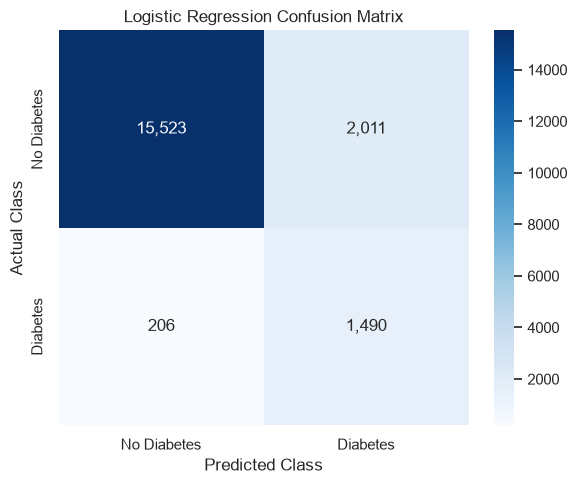

Random Forest
              precision    recall  f1-score   support

 No Diabetes       0.98      0.97      0.97     17534
    Diabetes       0.72      0.77      0.74      1696

    accuracy                           0.95     19230
   macro avg       0.85      0.87      0.86     19230
weighted avg       0.95      0.95      0.95     19230



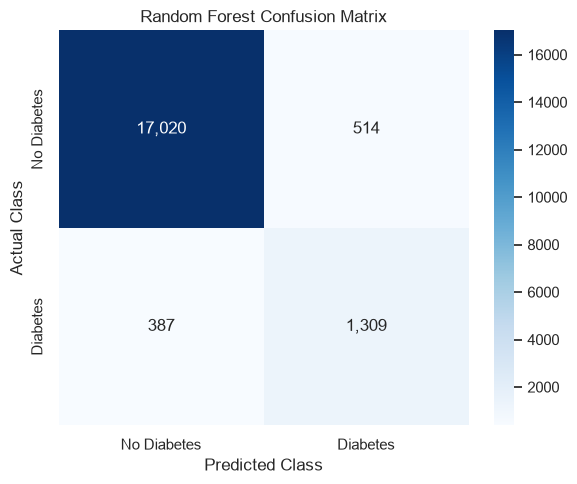

SVC
              precision    recall  f1-score   support

 No Diabetes       0.99      0.90      0.94     17534
    Diabetes       0.45      0.88      0.60      1696

    accuracy                           0.90     19230
   macro avg       0.72      0.89      0.77     19230
weighted avg       0.94      0.90      0.91     19230



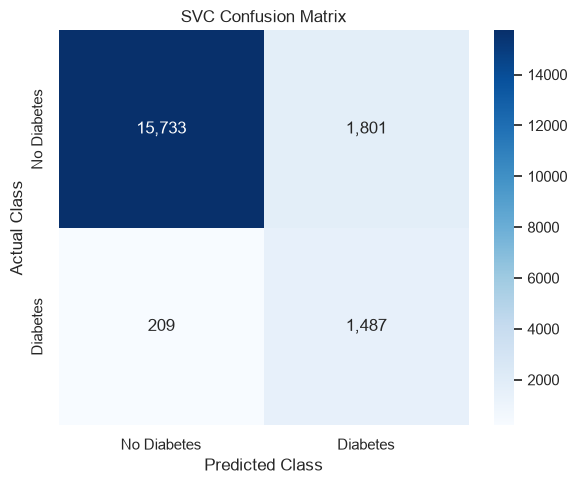

XGBoost
              precision    recall  f1-score   support

 No Diabetes       0.97      0.99      0.98     17534
    Diabetes       0.89      0.73      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.93      0.86      0.89     19230
weighted avg       0.97      0.97      0.97     19230



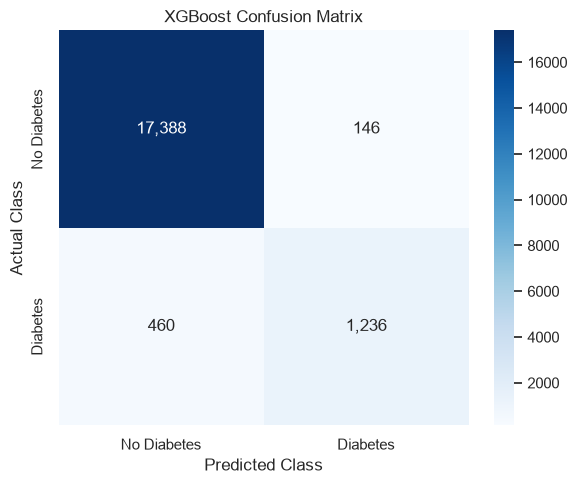

In [29]:
for model_name, pipeline in fitted_pipelines.items():
    y_pred = pipeline.predict(X_test)

    print("=" * 70)
    print(model_name)
    print("=" * 70)
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["No Diabetes", "Diabetes"],
            zero_division=0,
        )
    )

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt=",d",
        cmap="Blues",
        xticklabels=["No Diabetes", "Diabetes"],
        yticklabels=["No Diabetes", "Diabetes"],
    )
    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

1. ROC curve comparison

ROC curves compare the models over many classification thresholds.

A higher ROC-AUC generally indicates stronger class-separation ability.


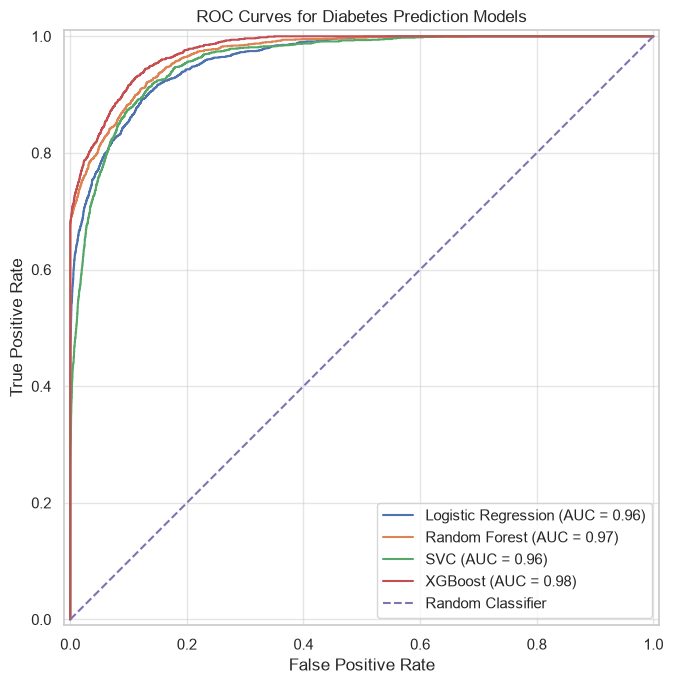

In [30]:
plt.figure(figsize=(9, 7))
ax = plt.gca()

for model_name, pipeline in fitted_pipelines.items():
    RocCurveDisplay.from_estimator(
        pipeline,
        X_test,
        y_test,
        name=model_name,
        ax=ax,
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curves for Diabetes Prediction Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

1. Select and save the best model

The model with the highest test ROC-AUC is selected in this educational example.

In a real clinical project, model selection should also consider:

- Recall
- False-negative rate
- Calibration
- Subgroup fairness
- External validation

In [31]:
# Create an output folder in  project
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

best_model_name = test_results.iloc[0]["Model"]
best_pipeline = fitted_pipelines[best_model_name]

MODEL_PATH = OUTPUT_DIR / "best_diabetes_pipeline.joblib"
joblib.dump(best_pipeline, MODEL_PATH)

print(f"Best model: {best_model_name}")
print(f"Saved to: {MODEL_PATH.resolve()}")

Best model: XGBoost
Saved to: C:\Users\User\PyCharmMiscProject\diabetes prediction model\output\best_diabetes_pipeline.joblib


1. Feature importance

Feature importance helps identify which variables influence the model most strongly.Importance does not prove causation. It only describes how the model uses the available data.

,Feature,Importance
0,HbA1c_level,2.385780
1,blood_glucose_level,1.302472
2,age,1.210385
3,gender_Female,0.984969
4,smoking_history_No Info,0.716994
5,gender_Male,0.686756
6,bmi,0.650253
7,smoking_history_not current,0.254036
8,smoking_history_never,0.199623
9,hypertension,0.192973


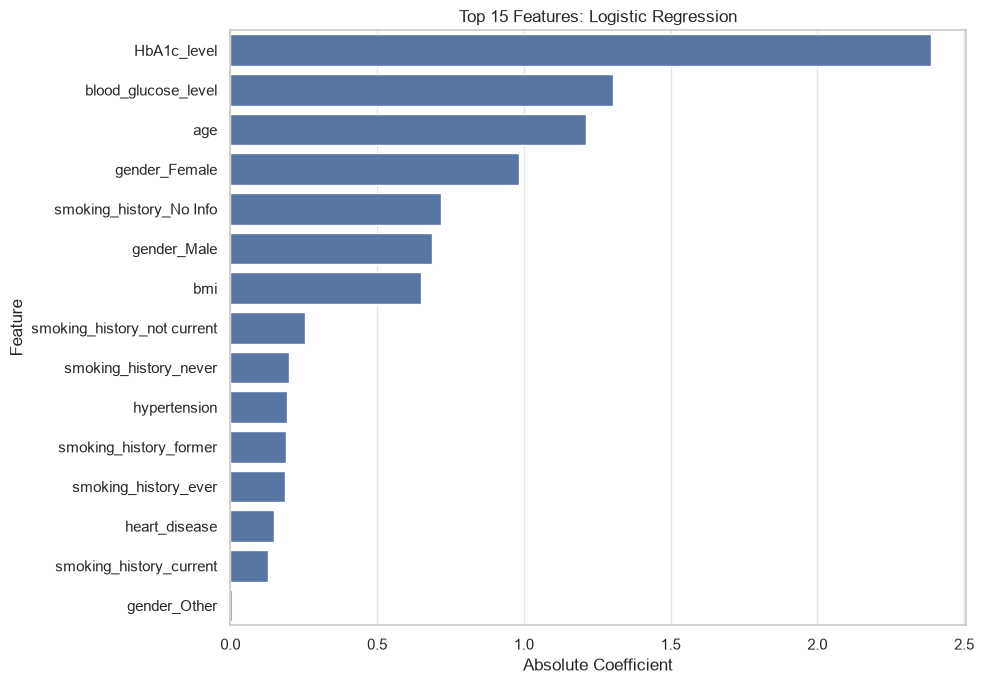

,Feature,Importance
0,HbA1c_level,0.376385
1,blood_glucose_level,0.283282
2,age,0.176486
3,bmi,0.098575
4,hypertension,0.023117
5,heart_disease,0.013051
6,smoking_history_No Info,0.011252
7,smoking_history_former,0.005022
8,smoking_history_never,0.002770
9,gender_Male,0.002659


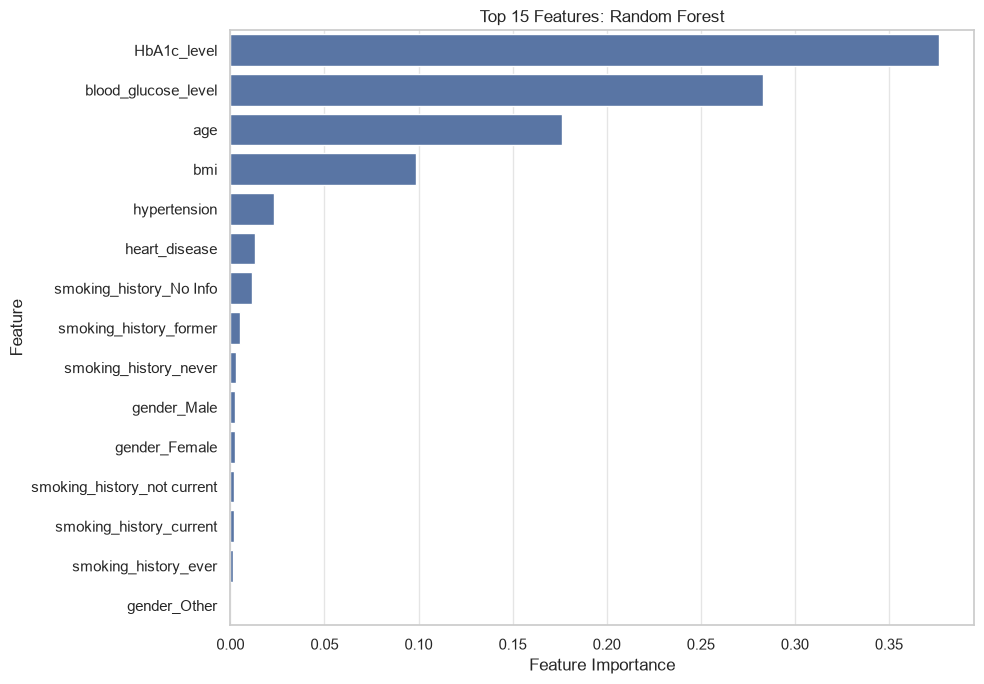

,Feature,Importance
0,HbA1c_level,0.335069
1,blood_glucose_level,0.259292
2,age,0.121754
3,hypertension,0.094003
4,bmi,0.069714
5,heart_disease,0.043585
6,smoking_history_No Info,0.036844
7,gender_Male,0.014109
8,smoking_history_not current,0.007416
9,gender_Female,0.005085


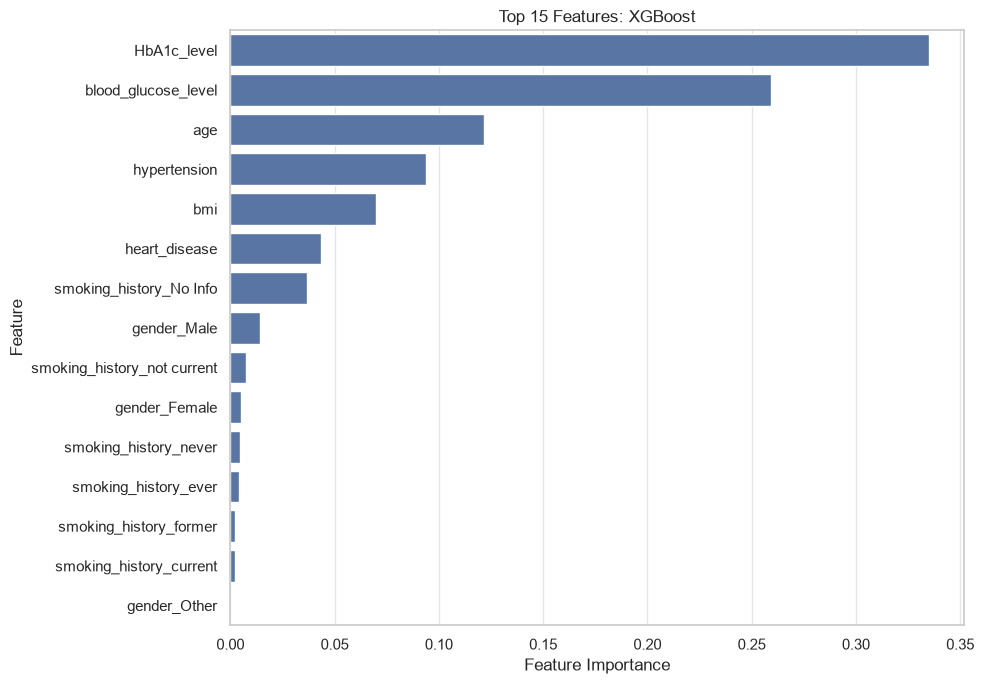

In [32]:
def get_feature_importance(model_name, fitted_pipeline):
    model = fitted_pipeline.named_steps["model"]
    feature_names = (
        fitted_pipeline.named_steps["preprocessor"]
        .get_feature_names_out()
    )

    if hasattr(model, "feature_importances_"):
        values = model.feature_importances_
        label = "Feature Importance"

    elif hasattr(model, "coef_"):
        values = np.abs(model.coef_[0])
        label = "Absolute Coefficient"

    else:
        print(f"{model_name} has no simple native importance output.")
        return None

    importance_df = (
        pd.DataFrame({
            "Feature": feature_names,
            "Importance": values,
        })
        .sort_values("Importance", ascending=False)
        .reset_index(drop=True)
    )

    display(importance_df.head(15))

    plt.figure(figsize=(10, 7))
    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature",
    )
    plt.title(f"Top 15 Features: {model_name}")
    plt.xlabel(label)
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

    return importance_df


for model_name in ["Logistic Regression", "Random Forest", "XGBoost"]:
    if model_name in fitted_pipelines:
        get_feature_importance(
            model_name,
            fitted_pipelines[model_name],
        )

1. SHAP model explanations

SHAP helps explain:

- Which features matter most overall
- Whether high or low feature values increase predictions
- Why the model produced a prediction for one patient

SHAP explanations describe model behaviour, not medical causality.

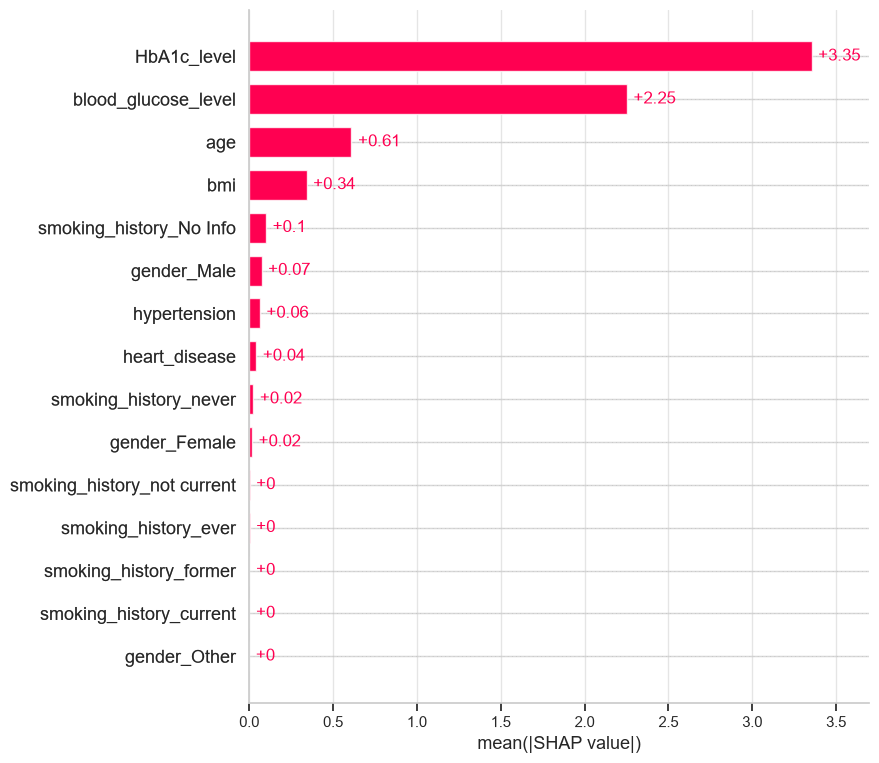

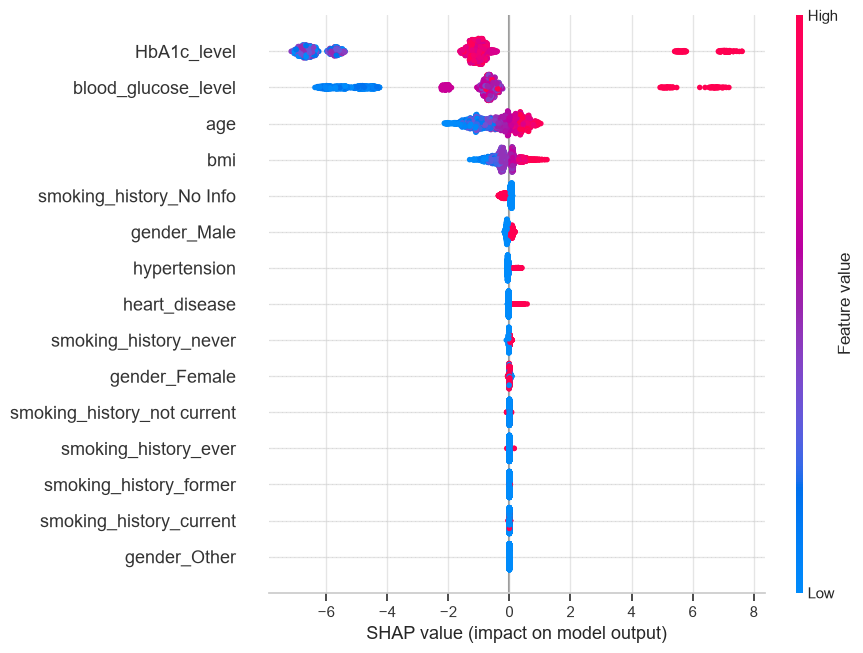

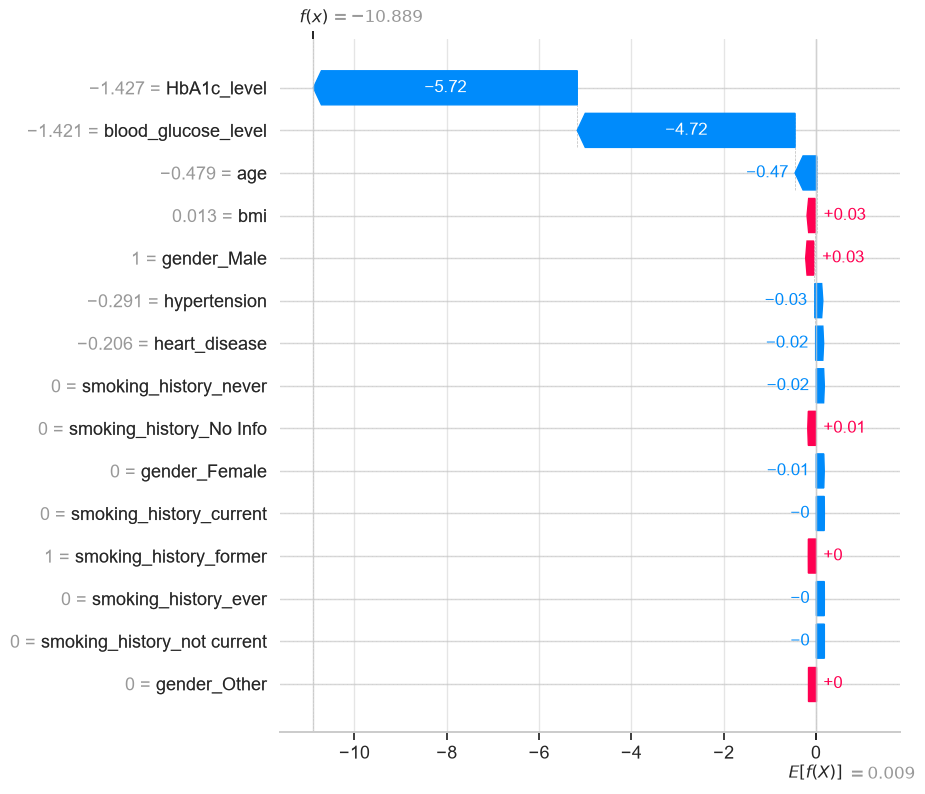

In [33]:
shap_model_name = (
    "XGBoost"
    if "XGBoost" in fitted_pipelines
    else "Random Forest"
)

shap_pipeline = fitted_pipelines[shap_model_name]
shap_preprocessor = shap_pipeline.named_steps["preprocessor"]
shap_model = shap_pipeline.named_steps["model"]

X_shap_sample = X_test.sample(
    n=min(2_000, len(X_test)),
    random_state=RANDOM_STATE,
)

X_shap_transformed = shap_preprocessor.transform(X_shap_sample)
shap_feature_names = shap_preprocessor.get_feature_names_out()

X_shap_df = pd.DataFrame(
    X_shap_transformed,
    columns=shap_feature_names,
    index=X_shap_sample.index,
)

explainer = shap.TreeExplainer(shap_model)
shap_values = explainer(X_shap_df)

if len(shap_values.values.shape) == 3:
    shap_values = shap.Explanation(
        values=shap_values.values[:, :, 1],
        base_values=shap_values.base_values[:, 1],
        data=shap_values.data,
        feature_names=shap_feature_names,
    )

shap.plots.bar(shap_values, max_display=15)
shap.plots.beeswarm(shap_values, max_display=15)
shap.plots.waterfall(shap_values[0], max_display=15)

1. Decision-threshold comparison

The default threshold is usually `0.50`.

Lowering the threshold can increase recall but usually creates more false positives. Threshold selection should be based on clinical objectives and validation data, not the final test set.


In [34]:
best_probabilities = best_pipeline.predict_proba(X_test)[:, 1]

threshold_rows = []

for threshold in [0.20, 0.30, 0.40, 0.50, 0.60]:
    threshold_predictions = (
            best_probabilities >= threshold
    ).astype(int)

    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            threshold_predictions,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_test,
            threshold_predictions,
            zero_division=0,
        ),
        "F1": f1_score(
            y_test,
            threshold_predictions,
            zero_division=0,
        ),
    })

threshold_results = pd.DataFrame(threshold_rows)

display(threshold_results.style.format({
    "Threshold": "{:.2f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1": "{:.4f}",
}))

,Threshold,Precision,Recall,F1
0,0.20,0.4526,0.9239,0.6076
1,0.30,0.5823,0.8514,0.6916
2,0.40,0.7501,0.7877,0.7685
3,0.50,0.8944,0.7288,0.8031
4,0.60,0.9734,0.6904,0.8079


1. Predict a new patient

The saved pipeline automatically applies the same preprocessing steps used during training.
the  example below is fictional and must not be interpreted as medical advice.

In [35]:
loaded_pipeline = joblib.load(MODEL_PATH)

new_patient = pd.DataFrame({
    "gender": ["Female"],
    "age": [52.0],
    "hypertension": [1],
    "heart_disease": [0],
    "smoking_history": ["former"],
    "bmi": [31.8],
    "HbA1c_level": [6.7],
    "blood_glucose_level": [180],
})

predicted_class = int(
    loaded_pipeline.predict(new_patient)[0]
)

predicted_probability = float(
    loaded_pipeline.predict_proba(new_patient)[0, 1]
)

display(new_patient)

print(f"Predicted class: {predicted_class}")
print(f"Predicted probability: {predicted_probability:.2%}")

if predicted_class == 1:
    print(
        "The model detected a higher-risk pattern. "
        "This is not a diagnosis."
    )
else:
    print(
        "The model did not classify this record as diabetes. "
        "This does not rule out diabetes."
    )

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
0,Female,52.0,1,0,former,31.8,6.7,180


Predicted class: 1
Predicted probability: 99.96%
The model detected a higher-risk pattern. This is not a diagnosis.


## 18. Ethics and limitations

### Dataset bias
The dataset may not represent every population equally. Performance can vary by age, gender, ethnicity, location and healthcare setting.

### Clinical limitations
A machine-learning prediction is not a diagnosis. Medical diagnosis requires validated clinical tests and professional interpretation.

### False negatives
A patient with diabetes may be predicted as negative. This may create false reassurance.

### False positives
A patient without diabetes may be predicted as positive, potentially causing anxiety or unnecessary testing.

### Data leakage
All preprocessing and SMOTE operations must be fitted only on training data.

### External validation
Performance on one dataset does not guarantee performance in another hospital, country or patient population.

### Explainability
Feature importance and SHAP explain model behaviour. They do not establish causal medical relationships.

### Privacy
Clinical data should be protected using appropriate access controls, encryption and data-protection procedures.
